In [1]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from ou_hankel import OUNetwork, theoretical_rank, theoretical_hankel, theoretical_whitened_hankel
from collections import Counter


plt.rcParams.update({
    # Font Family
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    
    # Consistent Font Sizes
    'font.size': 13,          # Base default text size
    'axes.labelsize': 13,     # X and Y axis labels
    'axes.titlesize': 13,     # Subplot titles
    'xtick.labelsize': 13,    # X-axis tick labels
    'ytick.labelsize': 13,    # Y-axis tick labels
    'legend.fontsize': 10,   # Legend text
    'figure.titlesize': 10,   # Overall figure title
})

In [2]:
n, h, margin = 40, 0.3, 0.3
M_list, p_list, n_graphs = [1, 3, 5, 10, 20], [0.005, 0.01, 0.02, 0.04], 10
EPS = np.finfo(float).eps

rec = []
for M in M_list:
    for p in p_list:
        for r in range(n_graphs):
            G = nx.erdos_renyi_graph(n, p, directed=True, seed=1000+31*r+int(1e4*p))
            s = OUNetwork(G, seed=100+r, weight_range=(0.2, 0.4), spectral_margin=margin)
            rng = np.random.default_rng(500 + r + 7*M)
            sens = sorted(rng.choice(n, M, replace=False).tolist())
            n_p = len(s.output_reachable_set(sens))
            H = theoretical_hankel(s, sens, h, 2*n)
            sv = np.linalg.svd(H, compute_uv=False)
            rec.append((M, n_p, np.linalg.matrix_rank(H), sv[0]/sv[min(n_p,len(sv))-1], max(H.shape)))


rec = np.array(rec, float)
M_, np_, rk_, cond, dim = rec.T
res = cond < 1 / (dim * EPS)                                   # representable in float64
print(f"resolvable (cond < 1/eps): {(rk_[res]==np_[res]).sum():.0f}/{res.sum():.0f} exact")

resolvable (cond < 1/eps): 166/166 exact


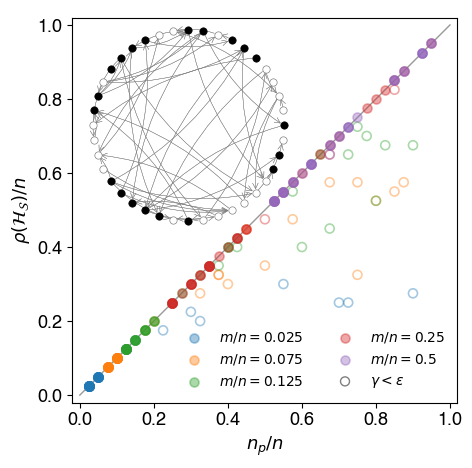

In [ ]:

fig, ax = plt.subplots(figsize=(5, 5))

# 1. Main Scatter Plot
ax.plot([0, 1], [0, 1], color="0.6", lw=1, zorder=0)
rj = np.random.default_rng(0)
cmap = plt.cm.tab20(np.linspace(0.0, 0.4, len(M_list)))

for c, M in zip(cmap, M_list):
    for mask, fc, lbl in [(res, c, f"$m/n={M/n}$"), (~res, "none", None)]:
        m = (M_ == M) & mask
        if not m.any():
            continue
        j = (rj.random(m.sum()) - 0.5) * 0
        ax.scatter(
            np_[m] / n + j,
            rk_[m] / n + j,
            s=42,
            facecolor=fc,
            edgecolor=c,
            linewidth=1.2,
            alpha=0.4,
            label=lbl,
            zorder=3,
        )

ax.scatter(
    [], [], s=42, facecolor="none", edgecolor="0.5", label=r"$\gamma < \epsilon$"
)
ax.set_xlabel(r"$n_p/n$")
ax.set_ylabel(r"$\rho(\mathcal{H}_{\mathcal{S}})/n$")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal")
ax.legend(frameon=False, loc="lower right", ncols=2)


# 2. Add Inset Network Diagram using the last `G` and `sens` from your loop
ax_inset = ax.inset_axes([0.001, 0.42, 0.6, 0.6])
ax_inset.set_frame_on(False)

sensor_nodes = sens
regular_nodes = [node for node in G.nodes() if node not in sensor_nodes]

# # Draw faint edges (disable arrows to keep 100-node graph readable)
# nx.draw_networkx_edges(
#     G, pos, ax=ax_inset, edge_color="gray", width=0.5, arrows=False
# )

# Regular nodes: Open / Unfilled black circles
nx.draw_circular(
    G,
    nodelist=regular_nodes,
    node_color="white",
    edgecolors="gray",
    edge_color="gray",
    node_shape="o",
    node_size=28,
    linewidths=0.5,
    width=0.3,
    arrowstyle="->",
    connectionstyle="arc3,rad=0.15",
    ax=ax_inset,
    with_labels=False,
)

# Sensor nodes: Filled black circles
nx.draw_circular(
    G,
    nodelist=sensor_nodes,
    node_color="black",
    edgecolors="black",
    edge_color="gray",
    node_shape="o",
    node_size=28,
    linewidths=0.5,
    width=0.3,
    connectionstyle="arc3,rad=0.15",
    arrowstyle="->",
    ax=ax_inset,
    with_labels=False,
)
plt.savefig(f"plots/Figure1.pdf")